# Мини-проект: Анализ продуктовых и маркетинговых метрик рекламных кампаний

## Описание проекта
В данном проекте проводится комплексный анализ эффективности рекламных объявлений на основе исторических данных. Были рассчитаны ключевые маркетинговые метрики (CTR, CPC, CR), изучены их распределения, выявлены скрытые закономерности в разрезе аудиторий и рекламных кампаний, а также обработаны статистические аномалии данных.

## Описание данных
* `ad_id` – идентификатор объявления
* `xyz_campaign_id` – идентификатор кампании в базе компании X
* `fb_campaign_id` – идентификатор кампании в Facebook
* `age`, `gender` – демографические срезы аудитории
* `interest` – код категории интересов пользователя
* `impressions` – число показов рекламы
* `clicks` – число кликов по объявлению
* `spent` – сумма, потраченная на показ объявления
* `total_conversion` – количество целевых действий на сайте
* `approved_conversion` – количество подтвержденных покупок


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка стилей графиков
sns.set_theme(
    style='whitegrid',
    rc={
       'figure.figsize': (16, 6),            # Размер холста (ширина, высота)
        'axes.grid': True,                   # Включаем сетку принудительно
        'grid.alpha': 0.3,                   # Делаем сетку легкой и полупрозрачной
        'grid.linestyle': '--',              # Делаем сетку пунктирной
        'axes.titlesize': 14,                # Размер шрифта для заголовков графиков
        'axes.titleweight': 'bold',          # Жирные заголовки
        'axes.labelsize': 12,                # Размер шрифта для подписей осей X и Y
    }
)

## Шаг 1. Первичный анализ и предобработка данных
Загрузим данные, проверим размерность таблицы, типы данных и наличие пропущенных значений.

In [2]:
df = pd.read_csv(r"..\data\conversion.csv")

In [3]:
print(f"Размерность датасета: {df.shape}")
df.info()
print("\nПропущенные значения:")
print(df.isna().sum())
print("\nУникальные значения по колонкам:")
print(df.nunique())

Размерность датасета: (1143, 11)
<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ad_id                1143 non-null   int64  
 1   xyz_campaign_id      1143 non-null   int64  
 2   fb_campaign_id       1143 non-null   int64  
 3   age                  1143 non-null   str    
 4   gender               1143 non-null   str    
 5   interest             1143 non-null   int64  
 6   Impressions          1143 non-null   int64  
 7   Clicks               1143 non-null   int64  
 8   Spent                1143 non-null   float64
 9   Total_Conversion     1143 non-null   int64  
 10  Approved_Conversion  1143 non-null   int64  
dtypes: float64(1), int64(8), str(2)
memory usage: 98.4 KB

Пропущенные значения:
ad_id                  0
xyz_campaign_id        0
fb_campaign_id         0
age                    0
gender                 0
interest      

## Шаг 2. Распределение числа показов (Impressions)
Построим график распределения числа показов для каждого объявления. Из-за сильной асимметрии данных (наличия как мелких объявлений, так и супер-хитов) применим логарифмирование шкалы.

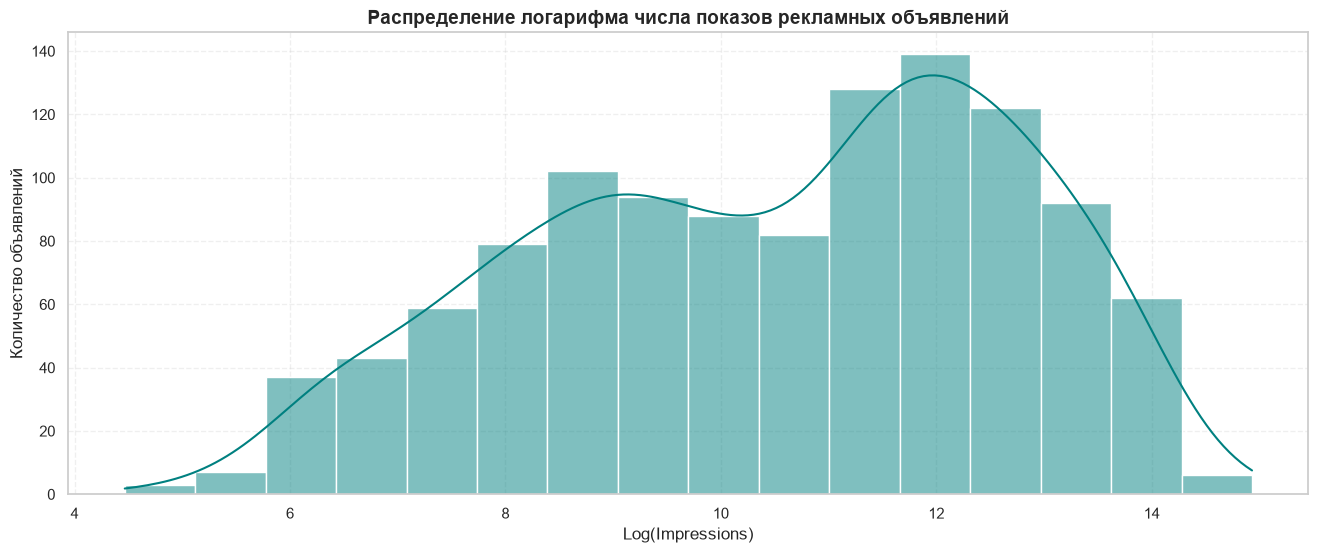

In [10]:
sns.histplot(np.log(df['Impressions']), kde=True, color='teal')
plt.title('Распределение логарифма числа показов рекламных объявлений')
plt.xlabel('Log(Impressions)')
plt.ylabel('Количество объявлений')
plt.show()

**Вывод по распределению показов:**
График имеет выраженную **бимодальную форму** (две вершины). Это указывает на то, что в данных смешаны две разные группы объявлений:
1. Тестовые / локальные объявления с небольшим бюджетом (пик в районе 8.5–9 по лог-шкале, около 5 000–10 000 показов).
2. Масштабные основные кампании (пик в районе 12 по лог-шкале, около 150 000–200 000 показов).

## Шаг 3. Расчет и анализ кликабельности (CTR)
Рассчитаем метрику CTR (Click-Through Rate) как отношение кликов к показам. Изучим описательные статистики.

In [5]:
df['CTR'] = df['Clicks'] / df['Impressions']
df['CTR'].describe()

count    1143.000000
mean        0.000164
std         0.000115
min         0.000000
25%         0.000100
50%         0.000160
75%         0.000234
max         0.001059
Name: CTR, dtype: float64

**Вывод по CTR:**
* Медианный CTR составляет **0.0159%** (в долях: 0.000160).
* Распределение имеет сильный **положительный скос (смещено вправо)**, так как среднее значение (0.0164%) выше медианы. Это вызвано наличием аномально кликабельных объявлений, где максимальный CTR достигает **0.1059%** (топ-перформеры).

## Шаг 4. Анализ CTR в разрезе рекламных кампаний
Сгруппируем данные по кампаниям и посмотрим на среднее, медиану и объем выборки.

In [6]:
df.groupby('xyz_campaign_id')['CTR'].agg(['mean', 'median', 'count'])

,mean,median,count
xyz_campaign_id,,,
916,0.000180,0.000188,54
936,0.000165,0.000179,464
1178,0.000162,0.000156,625


**Вывод по кампаниям:**
* Кампания **916** показывает самый высокий CTR, но имеет всего 54 объявления (высока вероятность случайности на малой выборке, кампания похожа на тестовую).
* Кампания **936** — наиболее стабильная и эффективная на объеме (464 объявления, высокая медиана).
* Кампания **1178** — самая массовая (625 объявлений), но её медиана самая низкая (0.0156%), что говорит о "выгорании" креативов при масштабировании.

## Шаг 5. Расчет стоимости клика (CPC) и анализ изменчивости
Рассчитаем метрику CPC (Cost Per Click) как отношение затрат к кликам. Строки с 0 кликов автоматически обработаны Pandas и заменены на NaN.

In [7]:
df['CPC'] = df['Spent'] / df['Clicks']
df['CPC'].describe()

count    936.000000
mean       1.499347
std        0.232879
min        0.180000
25%        1.390000
50%        1.498273
75%        1.644364
max        2.212000
Name: CPC, dtype: float64

**Вывод по CPC:**
В отличие от CTR, стоимость клика является **крайне предсказуемой и стабильной метрикой**. Среднее (1.499) практически равно медиане (1.498), а стандартное отклонение составляет всего 0.23. Распределение близко к нормальному, экономика затрат устойчива.

## Шаг 6. Визуализация CPC по полу пользователей
Посмотрим, как отличается стоимость клика для мужчин (M) и женщин (F).

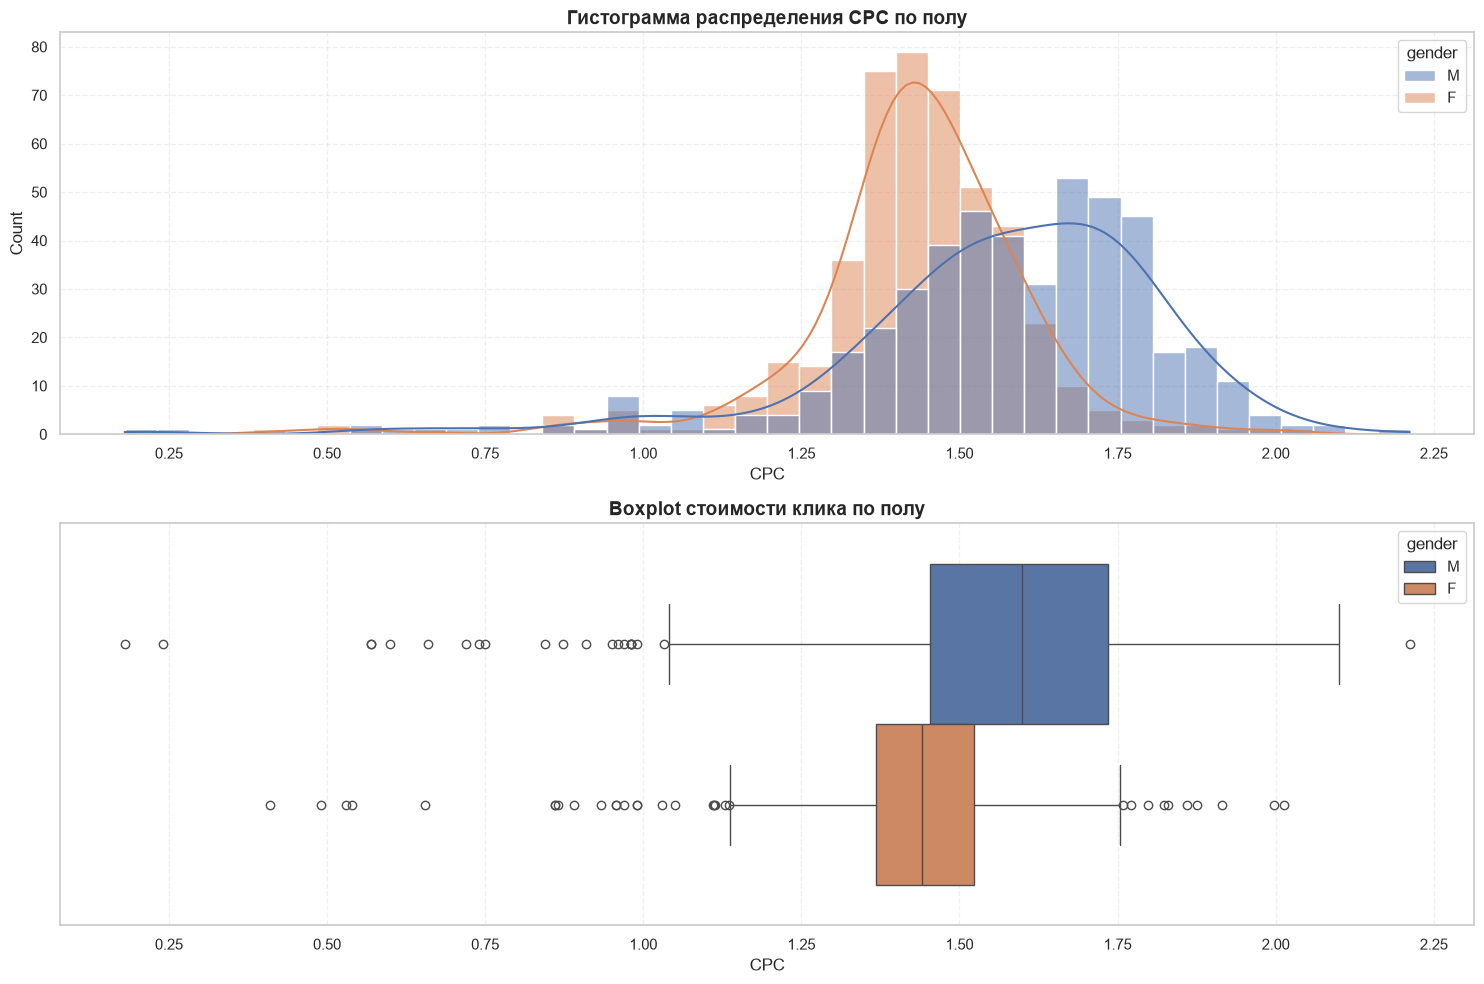

In [8]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(15, 10))

sns.histplot(df, x='CPC', hue='gender', ax=axes[0], kde=True)
axes[0].set_title('Гистограмма распределения CPC по полу')

sns.boxplot(df, x='CPC', hue='gender', ax=axes[1])
axes[1].set_title('Boxplot стоимости клика по полу')

plt.tight_layout()
plt.show()

**Вывод по сегментации аудитории:**
* Распределение CPC у женщин — **унимодальное** со стабильным пиком в районе 1.35–1.50. Однако у женщин присутствует длинный хвост "дорогих" выбросов (выше 1.75).
* Распределение CPC у мужчин — **бимодальное**. Существует отдельный дорогой сегмент мужчин с ценой клика 1.65–1.80, что указывает на высокую конкуренцию рекламодателей в данном таргетинге. При этом у мужчин почти нет выбросов за усы боксплота.

## Шаг 7. Расчет конверсии из клика в покупку (CR) и обработка аномалий
Посчитаем конверсию (Conversion Rate). Обработаем математические бесконечности (возникающие при делении покупок на 0 кликов вследствие ошибок трекинга).

In [9]:
df['CR'] = (df['Approved_Conversion'] / df['Clicks']) * 100

# Замена бесконечностей на NaN
df['CR'] = df['CR'].replace([np.inf, -np.inf], np.nan)
df['CR'].describe()

count    936.000000
mean      10.903023
std       24.703240
min        0.000000
25%        0.000000
50%        1.253931
75%        6.666667
max      200.000000
Name: CR, dtype: float64

**Вывод по конверсии (CR):**
* Типичная (медианная) конверсия из клика в покупку составляет **1.25%**, что является здоровым индустриальным стандартом для e-commerce / таргета.
* Максимальное значение составляет **200%**. Это техническая аномалия, вызванная либо особенностями окон атрибуции Facebook (покупки долетели позже кликов), либо совершением нескольких независимых покупок одним пользователем в рамках одного клика.
